# Tier 2 - Linear Kalman filter for pitch with a gyro-bias state

Estimators: **gyro** (integration), **accel** (tilt), **CF** (complementary filter, tau = 0.2 s) and **KF** (`kalman_pitch`, state = [pitch angle, y-axis gyro bias]). All scenarios use seed 0. Code works in rad, rad/s; tables state their units in the column headers. Ground-truth fields (`*_true`) are used only for metrics and plots, never passed to a filter.

## Q and R derivation (sensor specification -> filter noise)

Sensor specifications (datasheet-style constants, defined below and passed explicitly to the filter): gyro white noise sigma_g = 0.005 rad/s per sample, accelerometer white noise sigma_a = 0.05 m/s^2 per axis, bias random walk sigma_b = 1e-4 rad/s/sqrt(s), gravity G = 9.81 m/s^2.

- **State model.** The angle evolves as theta[k] = theta[k-1] + (w_meas - b - n_g) dt. The gyro white noise n_g (std sigma_g per sample) adds variance sigma_g^2 dt^2 to the angle each step, so **Q[0,0] = sigma_g^2 dt^2**.
- **Bias model.** The bias follows a random walk with increments ~ N(0, sigma_b^2 dt), so **Q[1,1] = sigma_b^2 dt**. Off-diagonal terms are zero because the two noise sources are independent. The trapezoidal average used in the prediction makes consecutive angle increments slightly correlated (per-step variance sigma_g^2 dt^2 / 2, but low-frequency power equal to sigma_g^2 dt^2 per step); the spec accepts this approximation and the tuning sweep at the end checks it empirically.
- **Measurement.** Accelerometer noise with std sigma_a on each axis perturbs the pitch from atan2 by about sigma_a / G. Only the noise perpendicular to gravity in the x-z plane matters to first order (std sigma_a for any pitch); the y-axis noise enters at second order. Hence **R = (sigma_a / G)^2**.
- **Numbers at dt = 0.01 s:** Q = diag(2.5e-9 rad^2, 1e-10 (rad/s)^2), R = (0.05/9.81)^2 = 2.598e-5 rad^2 (printed below from `kalman_noise_matrices`).
- **Initial covariance.** diag(R, 0.02^2): the initial angle comes from one accelerometer sample, and the bias is believed to be within +/-2x of the nominal 0.01 rad/s.
- **Integration rule.** The KF prediction uses the trapezoidal rate (w[k-1] + w[k]) / 2, which removes the half-sample lead of the backward-rectangle rule used by the Tier 1 functions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

import imu_sim
import imu_filters
import imu_metrics
import imu_plots

# Sensor-spec constants (the only noise information given to the filters)
GYRO_NOISE_STD = 0.005     # rad/s per sample
ACCEL_NOISE_STD = 0.05     # m/s^2 per axis
BIAS_RW_STD = 1e-4         # rad/s/sqrt(s)
GRAVITY = 9.81             # m/s^2
TAU = 0.2                  # s, complementary filter
DEG = np.rad2deg

Q, R = imu_filters.kalman_noise_matrices(0.01, GYRO_NOISE_STD, ACCEL_NOISE_STD, BIAS_RW_STD, GRAVITY)
print('Q at dt = 0.01 s [rad^2, (rad/s)^2]:'); print(Q)
print(f'R = {R:.6e} rad^2')

def run_estimators(sim):
    # Only measured data (t, gyro, accel) and sensor-spec constants go in; no *_true fields.
    accel_pitch = imu_filters.accel_tilt(sim.accel)[1]
    kf = imu_filters.kalman_pitch(sim.t, sim.gyro[:, 1], accel_pitch,
                                  gyro_noise_std=GYRO_NOISE_STD, accel_noise_std=ACCEL_NOISE_STD,
                                  bias_rw_std=BIAS_RW_STD, gravity=GRAVITY)
    est = {
        'gyro': imu_filters.gyro_integrate(sim.t, sim.gyro[:, 1], 0.0),
        'accel': accel_pitch,
        'CF': imu_filters.complementary_filter(sim.t, sim.gyro[:, 1], accel_pitch, tau=TAU),
        'KF': kf.angle,
    }
    return est, kf

def show(fig):
    display(fig)
    plt.close(fig)

Q at dt = 0.01 s [rad^2, (rad/s)^2]:
[[2.5e-09 0.0e+00]
 [0.0e+00 1.0e-10]]
R = 2.597778e-05 rad^2


## Standard run (S1: 60 s, 100 Hz, seed 0)

method      RMSE (deg)   max abs err (deg)
gyro           19.6836             34.5059
accel           0.2916              1.0575
CF              0.1402              0.3470
KF              0.0331              0.2006


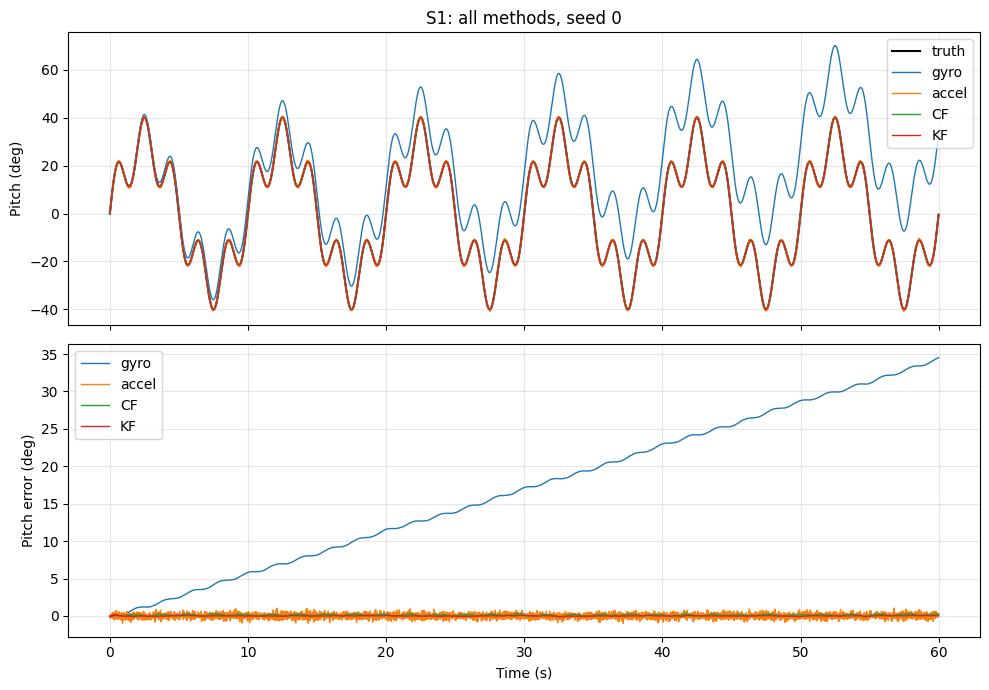

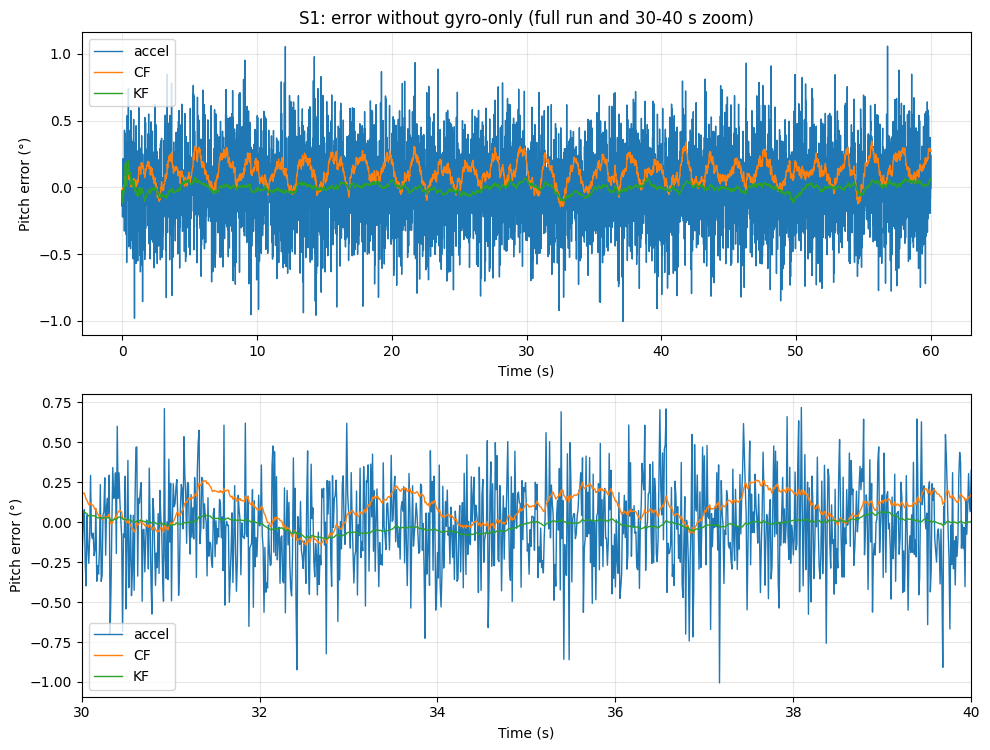

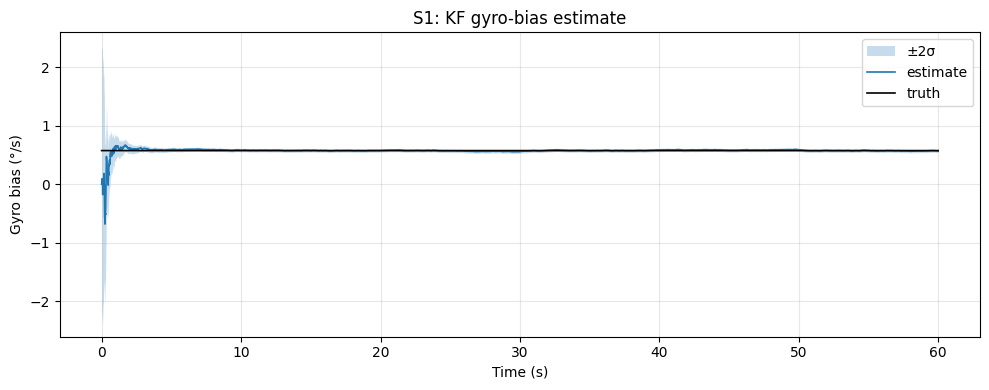

In [2]:
sim1 = imu_sim.simulate_pitch_imu(seed=0)
est1, kf1 = run_estimators(sim1)

print(f"{'method':<8}{'RMSE (deg)':>14}{'max abs err (deg)':>20}")
for name, est in est1.items():
    r = DEG(imu_metrics.rmse(est, sim1.pitch_true))
    m = DEG(imu_metrics.max_abs_error(est, sim1.pitch_true))
    print(f'{name:<8}{r:>14.4f}{m:>20.4f}')

show(imu_plots.plot_comparison(sim1.t, sim1.pitch_true, est1, title='S1: all methods, seed 0'))
show(imu_plots.plot_error_comparison(sim1.t, sim1.pitch_true, est1, exclude=('gyro',), t_window=(30, 40),
                                     title='S1: error without gyro-only (full run and 30-40 s zoom)'))
show(imu_plots.plot_bias_estimate(sim1.t, kf1.bias, np.sqrt(kf1.cov[:, 1, 1]),
                                  bias_true=sim1.gyro_bias_true[:, 1], title='S1: KF gyro-bias estimate'))

## Long run (S2: 600 s, seed 0)

method     drift (rad/s)   drift (deg/s)
gyro           9.991e-03       5.724e-01
accel          1.519e-07       8.701e-06
CF             1.777e-07       1.018e-05
KF             1.634e-07       9.364e-06


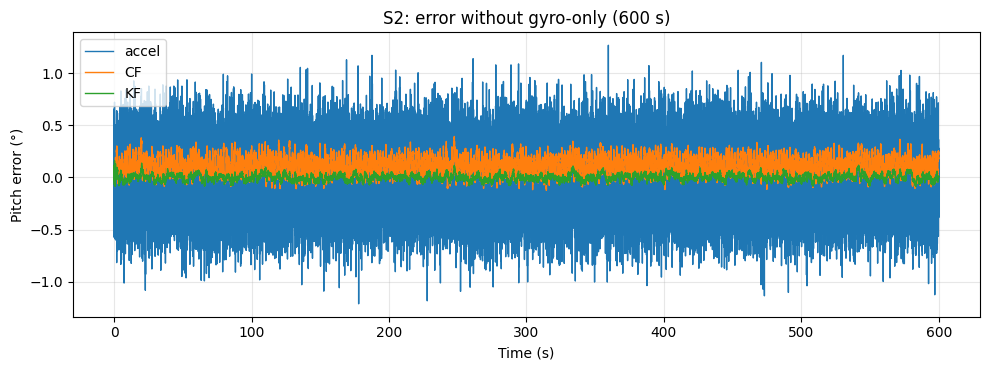

In [3]:
sim2 = imu_sim.simulate_pitch_imu(duration=600.0, seed=0)
est2, kf2 = run_estimators(sim2)

print(f"{'method':<8}{'drift (rad/s)':>16}{'drift (deg/s)':>16}")
for name, est in est2.items():
    d = imu_metrics.drift_rate(sim2.t, est, sim2.pitch_true)
    print(f'{name:<8}{d:>16.3e}{DEG(d):>16.3e}')

show(imu_plots.plot_error_comparison(sim2.t, sim2.pitch_true, est2, exclude=('gyro',),
                                     title='S2: error without gyro-only (600 s)'))

## Random-walk bias (S3: 600 s, bias random walk 1e-4 rad/s/sqrt(s), seed 0)

KF, samples with t >= 30 s
  angle RMSE : 0.0322 deg
  bias RMSE  : 2.533e-04 rad/s = 0.0145 deg/s
  bias coverage fraction (2 sigma, KC1): 0.933


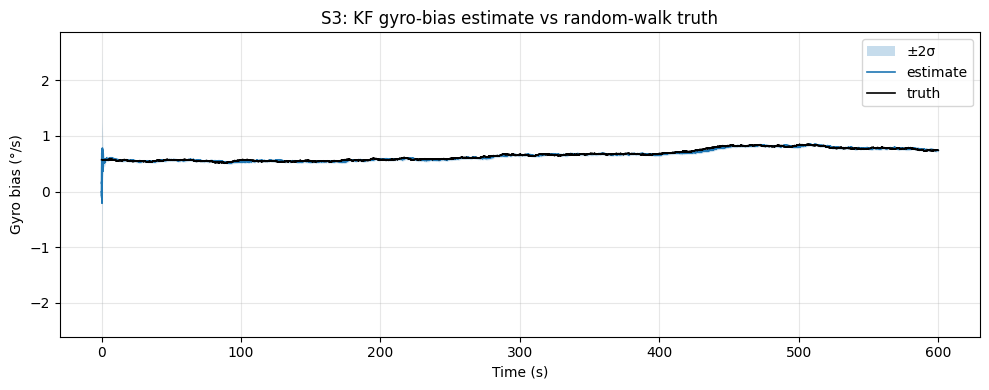

In [4]:
sim3 = imu_sim.simulate_pitch_imu(duration=600.0, gyro_bias_rw_std=1e-4, seed=0)
est3, kf3 = run_estimators(sim3)
m3 = sim3.t >= 30.0
bias_true3 = sim3.gyro_bias_true[:, 1]
ang_rmse = imu_metrics.rmse(kf3.angle[m3], sim3.pitch_true[m3])
bias_rmse = imu_metrics.rmse(kf3.bias[m3], bias_true3[m3])
cov_frac = imu_metrics.coverage_fraction(kf3.bias[m3], bias_true3[m3], np.sqrt(kf3.cov[m3, 1, 1]), 2.0)

print('KF, samples with t >= 30 s')
print(f'  angle RMSE : {DEG(ang_rmse):.4f} deg')
print(f'  bias RMSE  : {bias_rmse:.3e} rad/s = {DEG(bias_rmse):.4f} deg/s')
print(f'  bias coverage fraction (2 sigma, KC1): {cov_frac:.3f}')

show(imu_plots.plot_bias_estimate(sim3.t, kf3.bias, np.sqrt(kf3.cov[:, 1, 1]),
                                  bias_true=bias_true3, title='S3: KF gyro-bias estimate vs random-walk truth'))

## Bias step (S4: 120 s, +0.01 rad/s step on the y-axis bias at t = 60 s, seed 0)

KF bias convergence (|error| <= 1e-3 rad/s = 0.0573 deg/s): settled at t = 72.79 s, i.e. 12.79 s after the step
method      max abs angle err, 60-90 s (deg)
KF                                    0.4112
CF                                    0.4359


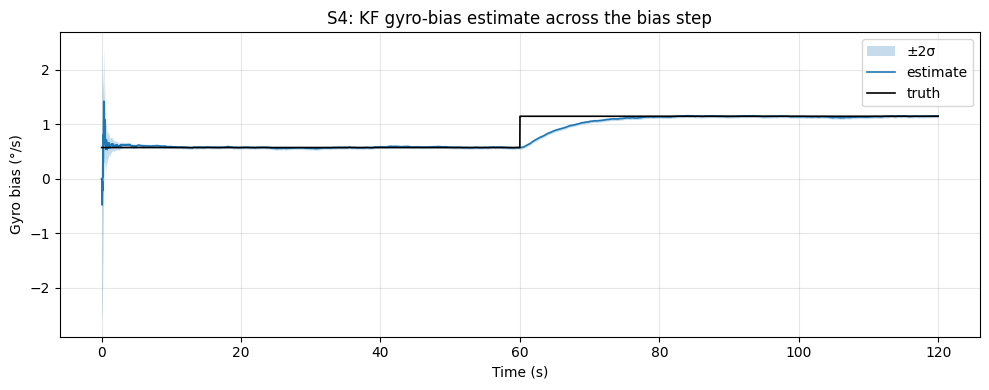

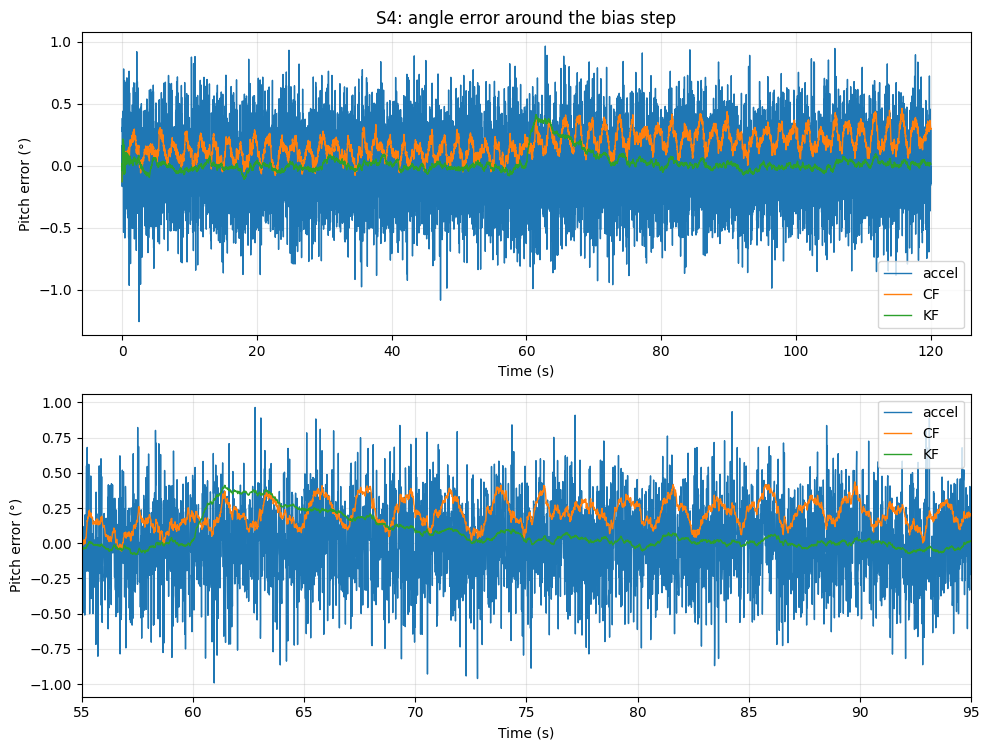

In [5]:
sim4 = imu_sim.simulate_pitch_imu(duration=120.0, bias_step=(60.0, 0.01), seed=0)
est4, kf4 = run_estimators(sim4)
bias_true4 = sim4.gyro_bias_true[:, 1]
T_STEP = 60.0
ct = imu_metrics.convergence_time(sim4.t, kf4.bias, bias_true4, tol=1e-3, t_start=T_STEP)
w4 = (sim4.t >= 60.0) & (sim4.t <= 90.0)
kf_max = imu_metrics.max_abs_error(est4['KF'][w4], sim4.pitch_true[w4])
cf_max = imu_metrics.max_abs_error(est4['CF'][w4], sim4.pitch_true[w4])

print(f'KF bias convergence (|error| <= 1e-3 rad/s = {DEG(1e-3):.4f} deg/s): '
      f'settled at t = {ct:.2f} s, i.e. {ct - T_STEP:.2f} s after the step')
print(f"{'method':<8}{'max abs angle err, 60-90 s (deg)':>36}")
print(f"{'KF':<8}{DEG(kf_max):>36.4f}")
print(f"{'CF':<8}{DEG(cf_max):>36.4f}")

show(imu_plots.plot_bias_estimate(sim4.t, kf4.bias, np.sqrt(kf4.cov[:, 1, 1]),
                                  bias_true=bias_true4, title='S4: KF gyro-bias estimate across the bias step'))
show(imu_plots.plot_error_comparison(sim4.t, sim4.pitch_true, est4, exclude=('gyro',), t_window=(55, 95),
                                     title='S4: angle error around the bias step'))

## Tuning sweep (S5: 120 s, bias random walk 1e-4 rad/s/sqrt(s), seed 0 only)

The KF is rerun with the sensor-spec noise scaled by sQ (gyro noise and bias random walk by sqrt(sQ)) and sR (accelerometer noise by sqrt(sR)). The metric is the KF angle RMSE (deg) over t >= 30 s. The cell (sQ, sR) = (1, 1) is the nominal tuning.

KF angle RMSE (deg), t >= 30 s; rows = sQ, columns = sR
   sQ/sR       0.1       0.3         1         3        10
     0.1    0.0280    0.0283    0.0336    0.0431    0.0594
     0.3    0.0317    0.0280    0.0285    0.0336    0.0443
       1    0.0398    0.0322    0.0280    0.0283    0.0336   <- (1, 1) row
       3    0.0506    0.0398    0.0317    0.0280    0.0285
      10    0.0669    0.0519    0.0398    0.0322    0.0280

value at (1, 1) = 0.0280 deg; grid minimum = 0.0280 deg; grid maximum = 0.0669 deg
(1, 1) / minimum = 1.000;  maximum / (1, 1) = 2.388


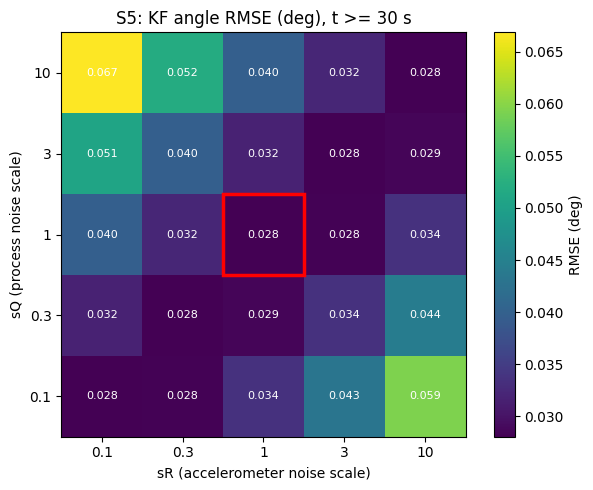

In [6]:
sim5 = imu_sim.simulate_pitch_imu(duration=120.0, gyro_bias_rw_std=1e-4, seed=0)
acc5 = imu_filters.accel_tilt(sim5.accel)[1]
m5 = sim5.t >= 30.0
SCALES = [0.1, 0.3, 1.0, 3.0, 10.0]
grid = np.zeros((len(SCALES), len(SCALES)))   # rows: sQ, columns: sR
for i, sQ in enumerate(SCALES):
    for j, sR in enumerate(SCALES):
        k = imu_filters.kalman_pitch(sim5.t, sim5.gyro[:, 1], acc5,
                                     gyro_noise_std=GYRO_NOISE_STD * np.sqrt(sQ),
                                     accel_noise_std=ACCEL_NOISE_STD * np.sqrt(sR),
                                     bias_rw_std=BIAS_RW_STD * np.sqrt(sQ), gravity=GRAVITY)
        grid[i, j] = DEG(imu_metrics.rmse(k.angle[m5], sim5.pitch_true[m5]))

print('KF angle RMSE (deg), t >= 30 s; rows = sQ, columns = sR')
print(f"{'sQ/sR':>8}" + ''.join(f'{s:>10g}' for s in SCALES))
for i, sQ in enumerate(SCALES):
    print(f'{sQ:>8g}' + ''.join(f'{grid[i, j]:>10.4f}' for j in range(len(SCALES))) + ('   <- (1, 1) row' if sQ == 1.0 else ''))
c = SCALES.index(1.0)
print(f'\nvalue at (1, 1) = {grid[c, c]:.4f} deg; grid minimum = {grid.min():.4f} deg; grid maximum = {grid.max():.4f} deg')
print(f'(1, 1) / minimum = {grid[c, c] / grid.min():.3f};  maximum / (1, 1) = {grid.max() / grid[c, c]:.3f}')

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(grid, origin='lower', cmap='viridis')
ax.set_xticks(range(len(SCALES)), [f'{s:g}' for s in SCALES])
ax.set_yticks(range(len(SCALES)), [f'{s:g}' for s in SCALES])
ax.set_xlabel('sR (accelerometer noise scale)')
ax.set_ylabel('sQ (process noise scale)')
ax.set_title('S5: KF angle RMSE (deg), t >= 30 s')
for i in range(len(SCALES)):
    for j in range(len(SCALES)):
        ax.text(j, i, f'{grid[i, j]:.3f}', ha='center', va='center', color='white', fontsize=8)
ax.add_patch(plt.Rectangle((c - 0.5, c - 0.5), 1, 1, fill=False, edgecolor='red', linewidth=2.5))
fig.colorbar(im, ax=ax, label='RMSE (deg)')
fig.tight_layout()
show(fig)

## Discussion

- **Standard run.** The KF has the lowest angle error of the four methods. Its RMSE is well below the complementary filter's because it estimates the gyro bias instead of merely high-pass filtering around it: the CF keeps a steady offset of about b*tau (0.01 rad/s x 0.2 s = 0.002 rad = 0.11 deg), whereas the KF bias estimate converges to the true bias, so that offset disappears and the KF noise floor is set by the Q/R balance.
- **Long run.** Gyro integration drifts at roughly the bias rate, while accel, CF and KF show essentially zero drift (values in the table are given in both rad/s and deg/s).
- **Random-walk bias.** With the sensor-spec random-walk intensity given to the filter, the KF tracks the wandering bias; the 2-sigma band from `cov[:, 1, 1]` should contain the true bias most of the time (coverage fraction printed above, compared with 0.95 for a perfectly calibrated Gaussian).
- **Bias step: KF vs CF.** At t = 60 s the bias jumps by 0.01 rad/s. Both filters show an angle transient of a few tenths of a degree right after the step. The CF's error then settles to a new, larger constant offset (about b*tau with the new bias of 0.02 rad/s, i.e. 0.004 rad = 0.23 deg), because it never learns the bias. The KF's bias estimate re-converges within roughly 10-15 s (about 5 s time constant), after which its angle error returns to its low noise floor. In the short window right at the step the two peak errors are of similar size, but only the KF recovers.
- **Tuning.** The sweep shows the KF is insensitive near the nominal setting but degrades markedly when Q and R are strongly mismatched (too small process noise: slow bias tracking; too large: noisy estimates). The datasheet-derived (1, 1) tuning is at or very near the grid minimum, which supports the Q/R derivation above, including the approximation made for the trapezoidal increments.